In [1]:
import pandas as pd

df = pd.read_csv("../data/cleaned_delivery_data.csv")

df.head()

,order_id,purchase_dayofweek,purchase_month,purchase_hour,purchase_is_weekend,estimated_delivery_days,n_items,n_sellers,total_price,total_freight,...,product_width_cm,payment_installments,payment_value,payment_type,customer_state,seller_state,product_category_name_english,distance_km,same_state,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,0,10,10,0,15.544063,1,1,0.002168,0.004858,...,13.0,1.0,0.002133,voucher,SP,SP,housewares,0.002153,1,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,1,7,20,0,19.137766,1,1,0.008769,0.012680,...,19.0,1.0,0.009658,boleto,BA,SP,perfumery,0.099222,0,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2,8,8,0,26.639711,1,1,0.011835,0.010708,...,21.0,3.0,0.012416,credit_card,GO,SP,auto,0.059294,0,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,5,11,19,1,26.188819,1,1,0.003285,0.015154,...,20.0,1.0,0.004585,credit_card,RN,MG,pet_shop,0.209937,0,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,1,2,21,0,12.112049,1,1,0.001418,0.004858,...,15.0,1.0,0.001394,credit_card,SP,SP,stationery,0.003410,1,2.873877


In [2]:
# Define target variable
y = df['delivery_time_days']

# Remove target column and order ID from predictors
X = df.drop(
    ['delivery_time_days', 'order_id'],
    axis=1
)

In [3]:
# Convert categorical variables into numerical format
# using one-hot encoding
X = pd.get_dummies(
    X,
    drop_first=True
)

In [4]:
# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [5]:
# Import Linear Regression algorithm
from sklearn.linear_model import LinearRegression

# Create model
lr = LinearRegression()

# Train model
lr.fit(X_train, y_train)

# Generate predictions
lr_pred = lr.predict(X_test)


In [6]:
# Import Decision Tree algorithm
from sklearn.tree import DecisionTreeRegressor

# Create Decision Tree model
dt = DecisionTreeRegressor(
    random_state=42
)

# Train model
dt.fit(X_train, y_train)

# Generate predictions
dt_pred = dt.predict(X_test)

In [7]:
# Import Random Forest algorithm
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
# n_estimators represents the number of trees
# n_jobs=-1 uses all available CPU cores
rf = RandomForestRegressor(
    n_estimators=20,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf.fit(X_train, y_train)

# Generate predictions
rf_pred = rf.predict(X_test)

In [8]:
# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create evaluation function
def evaluate(y_true, pred):

    # Calculate Mean Absolute Error
    mae = mean_absolute_error(
        y_true,
        pred
    )

    # Calculate Root Mean Squared Error
    rmse = mean_squared_error(
        y_true,
        pred
    ) ** 0.5

    # Calculate R-squared score
    r2 = r2_score(
        y_true,
        pred
    )

    return mae, rmse, r2


In [9]:
# Evaluate Linear Regression
evaluate(y_test, lr_pred)

# Evaluate Decision Tree
evaluate(y_test, dt_pred)

# Evaluate Random Forest
evaluate(y_test, rf_pred)

(3.599020301029192, 4.720658402909505, 0.39723661417176803)

In [24]:
# Evaluate Tuned Random Forest
evaluate(y_test, rf_tuned_pred)

(3.5373726300851733, 4.628231489091175, 0.4206088473435582)

In [10]:
# Create feature importance dataframe
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

# Sort features by importance score
importance = importance.sort_values(
    'Importance',
    ascending=False
)

# Display top 10 features
importance.head(10)

,Feature,Importance
17,same_state,0.196473
4,estimated_delivery_days,0.116658
16,distance_km,0.116424
1,purchase_month,0.068116
8,total_freight,0.055015
10,product_weight_g,0.042582
2,purchase_hour,0.036844
12,product_height_cm,0.035695
11,product_length_cm,0.033026
13,product_width_cm,0.032378


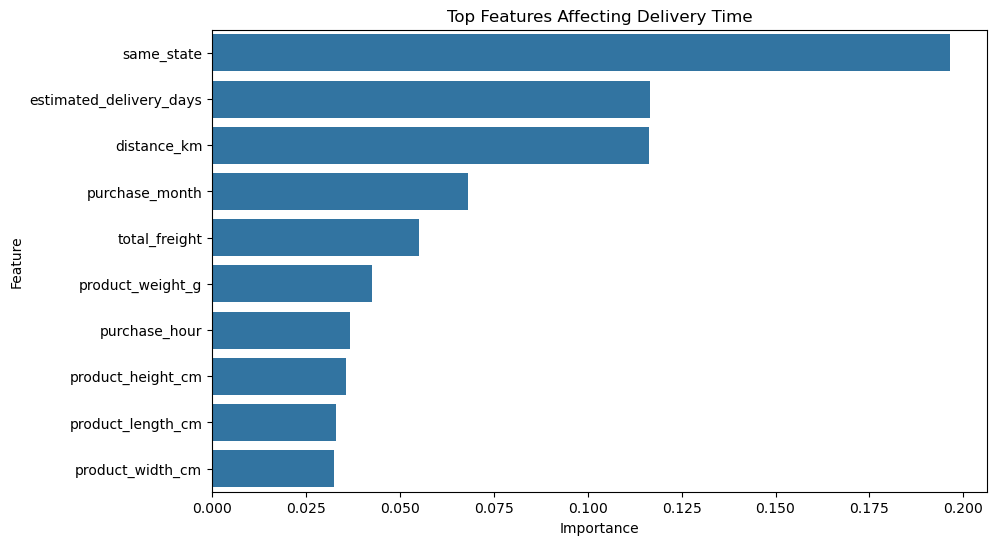

In [15]:
# Create feature importance chart
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance.head(10)
)

plt.title(
    "Top Features Affecting Delivery Time"
)

plt.savefig("../images/feature_importance.png",
            bbox_inches='tight')

plt.show()

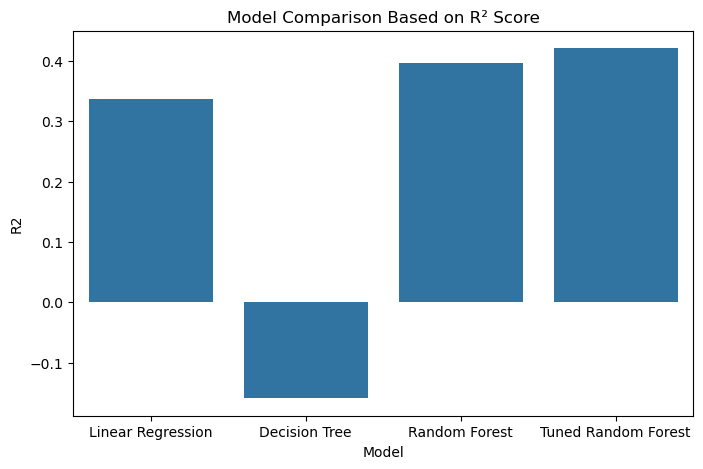

In [25]:
# Create model comparison dataframe
results = pd.DataFrame({
    'Model': ['Linear Regression',
              'Decision Tree',
              'Random Forest',
            'Tuned Random Forest'],
    'R2': [0.337, -0.159, 0.397,0.421]
})

# Plot model performance comparison
plt.figure(figsize=(8,5))

sns.barplot(
    x='Model',
    y='R2',
    data=results
)

plt.title(
    "Model Comparison Based on R² Score"
)


plt.savefig("../images/model_comparison.png",
            bbox_inches='tight')

plt.show()

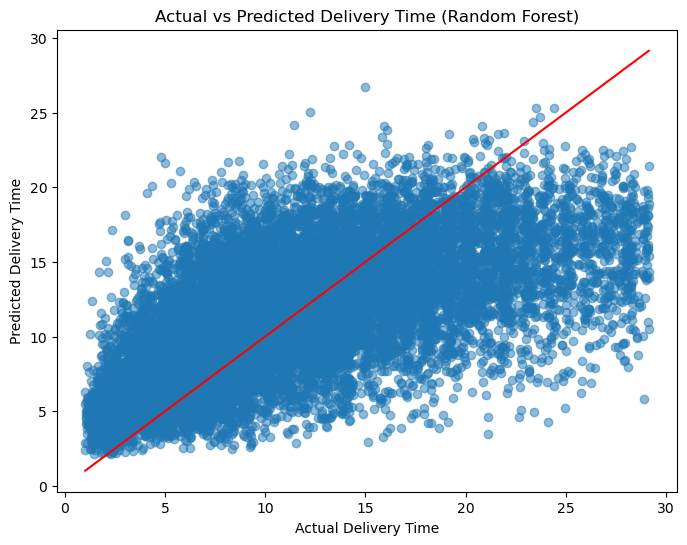

In [23]:
# Compare predicted and actual delivery times
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.5
)

# Label axes
plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")

plt.title(
    "Actual vs Predicted Delivery Time (Random Forest)"
)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)


plt.savefig("../images/Actual_vs_Predicted Scatter .png",
            bbox_inches='tight')
plt.show()

In [22]:
# Create tuned Random Forest model
rf_tuned = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)
# Train tuned model

rf_tuned.fit(X_train, y_train)

# Generate predictions

rf_tuned_pred = rf_tuned.predict(X_test)